# Assignment 2 — Final Test Evaluation

**Purpose:** Evaluate frozen models once on the previously inspected chronological benchmark.

This notebook is an executable evidence view over the shared local pipeline. The
command-line runner and notebook call the same stage implementation, preventing code
drift. Completed artifacts are reused; no Google Colab or Google Drive runtime is used.


In [1]:
# Local WSL project bootstrap. Dependency installation belongs to the
# locked project environment and is intentionally not repeated in notebooks.
from pathlib import Path
import json
import os
import platform
import sys

candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [candidate, *candidate.parents] if (path / "shared").exists()),
    candidate,
)
if not (PROJECT_ROOT / "shared").exists():
    raise FileNotFoundError(
        "Open this notebook from the local odl-assignment project root."
    )
os.environ["ODL_PROJECT_ROOT"] = str(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.config import PATHS
from shared.runtime import RuntimeOptions
from shared.workflow import run_stage

OPTIONS = RuntimeOptions.from_environment()
print("Project root:", PROJECT_ROOT)
print("Run mode:", OPTIONS.mode)
print("Device policy:", OPTIONS.device)
print("WSL distribution:", os.getenv("WSL_DISTRO_NAME", "not detected"))


I0000 00:00:1786699784.178789   26893 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root: /home/nicholas/code/odl-assignment
Run mode: full
Device policy: gpu
WSL distribution: Ubuntu-24.04


I0000 00:00:1786699785.196483   26893 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Run the shared stage or load its verified completed result.
STAGE_SUMMARY = run_stage("evaluate", options=OPTIONS)
STAGE_SUMMARY


{'winner': 'tuned_final',
 'winner_mae': 9.515844883821591,
 'tuned_mae': 9.515844883821591,
 'persistence_mae': 10.837475173990686,
 'improvement_over_persistence_percent': 12.195001778098012,
 'test_anchors': 59917,
 'statistically_superior_to_basic_lstm': False,
 'tuned_is_observed_mae_winner': True,
 'run_mode': 'full'}

In [3]:
# Record the exact runtime used for this output when preflight evidence exists.
environment_path = PATHS.environment_artifacts / f"environment_{OPTIONS.mode}.json"
ENVIRONMENT = (
    json.loads(environment_path.read_text(encoding="utf-8"))
    if environment_path.exists()
    else {"status": "preflight evidence not yet generated"}
)
ENVIRONMENT


{'captured_at_utc': '2026-08-14T09:29:07.880963+00:00',
 'project_root': '/home/nicholas/code/odl-assignment',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'system': 'Linux',
 'release': '6.6.87.2-microsoft-standard-WSL2',
 'python': '3.12.3',
 'wsl_distribution': 'Ubuntu-24.04',
 'device': 'gpu',
 'tensorflow_gpu_devices': ['/physical_device:GPU:0'],
 'batch_size': 256,
 'mixed_precision': False,
 'nvidia_smi': {'available': True,
  'name': 'NVIDIA GeForce RTX 3050 Laptop GPU',
  'driver_version': '591.74',
  'memory.total': '4096',
  'memory.used': '167',
  'utilization.gpu': '3',
  'temperature.gpu': '62',
  'power.draw': '18.49'},
 'packages': {'tensorflow': '2.21.0',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'pyarrow': '25.0.0',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1',
  'seaborn': '0.13.2'},
 'git': {'available': True,
  'revision': '4e8a886f8c5ec31e376ce1fd0a256c49b441fea9',
  'dirty': True},
 'experiment_config': {'methodology_versi

## Overall comparison and computational evidence

**Decision.** MAE is primary because it is interpretable in µg/m³ and less dominated by
spikes; RMSE exposes large misses, R² measures explained variation, and sMAPE provides
relative error. Parameter and timing evidence adds efficiency. **Trade-off.** No single
metric captures public-health costs, so all claims use the metric panel and subgroup
evidence. This period is called a frozen benchmark—not untouched—because aggregate
results from the earlier methodology were already inspected.


In [4]:
import pandas as pd
from IPython.display import Image, display

suffix = OPTIONS.artifact_suffix
overall_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_overall_metrics{suffix}.csv"
)
inference = pd.read_csv(
    PATHS.assignment2_tables / f"inference_timing{suffix}.csv"
)
display(overall_metrics)
display(inference)


,model,n,mae,rmse,r2,smape_percent
0,tuned_final,59917,9.515845,19.231013,0.957815,18.604818
1,basic_lstm,59917,9.618338,19.154359,0.958150,18.632723
2,basic_cnn,59917,10.001001,19.281143,0.957594,20.141896
3,persistence,59917,10.837475,21.696115,0.946307,21.023500
4,daily_persistence,59917,65.334413,98.666703,-0.110450,84.401773


,model,inference_seconds,parameters
0,basic_lstm,1.355080,29249
1,basic_cnn,1.966511,22913
2,tuned_final,1.797872,62273


## Robustness by station, season, and pollution intensity

Grouped metrics expose where aggregate performance hides difficult conditions. Seed
tables compare every model rather than only the winner.


In [5]:
station_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_station{suffix}.csv"
)
season_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_season{suffix}.csv"
)
pollution_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_pollution_band{suffix}.csv"
)
residual_diagnostics = pd.read_csv(
    PATHS.assignment2_tables / f"residual_diagnostics{suffix}.csv"
)
display(station_metrics)
display(season_metrics)
display(pollution_metrics)
display(residual_diagnostics)


,model,station,n,mae,rmse,r2,smape_percent
0,persistence,Aotizhongxin,5029,11.054683,21.011762,0.950379,21.138972
1,persistence,Changping,5033,10.634810,20.288271,0.938301,23.139755
2,persistence,Dingling,4877,8.952430,18.320451,0.938530,22.563145
3,persistence,Dongsi,4973,11.886588,23.928558,0.946226,18.960286
4,persistence,Guanyuan,4989,11.622169,22.386951,0.944607,21.042844
5,persistence,Gucheng,4992,11.127804,23.057247,0.948558,18.855742
6,persistence,Huairou,5016,8.882974,19.669341,0.935236,20.742573
7,persistence,Nongzhanguan,5003,11.307615,21.963646,0.951553,21.425277
8,persistence,Shunyi,4943,11.356261,22.214876,0.943048,21.034552
9,persistence,Tiantan,5018,11.170387,20.766581,0.952406,22.928507


,model,season,n,mae,rmse,r2,smape_percent
0,persistence,autumn,25483,9.446141,16.847153,0.945001,19.404030
1,persistence,summer,8854,6.470296,10.058346,0.911759,20.505897
2,persistence,winter,25580,13.735145,28.014643,0.944012,22.815986
3,daily_persistence,autumn,25483,54.495978,75.133787,-0.093890,78.437521
4,daily_persistence,summer,8854,29.409419,40.111260,-0.403301,65.409308
5,daily_persistence,winter,25580,88.566458,128.927742,-0.185820,96.917266
6,basic_lstm,autumn,25483,8.267740,14.652787,0.958395,17.046701
7,basic_lstm,summer,8854,5.666778,8.497036,0.937027,17.664547
8,basic_lstm,winter,25580,12.331567,24.909809,0.955734,20.547844
9,basic_cnn,autumn,25483,8.662099,14.898909,0.956986,18.372606


,model,pollution_band,n,mae,rmse,r2,smape_percent
0,persistence,low,18070,4.857056,13.960267,-6.507983,35.643756
1,persistence,moderate,25329,9.836472,18.223348,0.499467,17.830029
2,persistence,high,8375,15.162269,23.956313,-0.378413,11.116125
3,persistence,extreme,8143,22.774162,37.522105,0.834213,8.702935
4,daily_persistence,low,18070,61.093138,106.890376,-439.162538,105.952368
5,daily_persistence,moderate,25329,48.239567,68.989836,-6.173749,82.474935
6,daily_persistence,high,8375,71.012537,85.987485,-16.758643,66.971410
7,daily_persistence,extreme,8143,122.080192,154.493874,-1.810594,60.499633
8,basic_lstm,low,18070,4.029004,11.882614,-4.439511,31.648193
9,basic_lstm,moderate,25329,8.573603,15.213671,0.651146,15.626113


,model,mean_residual,median_residual,underprediction_percent,extreme_mean_residual,extreme_underprediction_percent
0,persistence,-0.002587,1.000000,50.114325,4.496377,55.163944
1,daily_persistence,-0.423553,7.000000,56.414707,88.926563,81.063490
2,basic_lstm,-0.805936,-0.544132,46.859823,2.602264,51.197347
3,basic_cnn,-1.466428,-1.640147,40.814794,4.591503,54.083262
4,tuned_final,-0.399730,-0.353622,47.761069,4.400394,54.979737


## Temporal uncertainty and diagnostic plots

Paired moving-block intervals resample complete calendar days, retaining every station
within a day. One-day intervals are a sensitivity check; seven-day blocks are the
official superiority test because they preserve short-range temporal dependence.
Diagnostic plots reveal bias, extremes, and time-local behaviour.


,comparison,analysis,mean_mae_difference_a_minus_b,ci95_lower,ci95_upper,block_length_days,n_calendar_days,n_rows,bootstrap_samples,seed
0,tuned_final_vs_basic_lstm,sensitivity,-0.102493,-0.184090,-0.022711,1,212,59917,10000,42
1,tuned_final_vs_basic_lstm,official,-0.102493,-0.207160,0.001681,7,212,59917,10000,42
2,tuned_final_vs_basic_cnn,sensitivity,-0.485157,-0.585908,-0.386261,1,212,59917,10000,42
3,tuned_final_vs_basic_cnn,official,-0.485157,-0.612827,-0.350022,7,212,59917,10000,42
4,tuned_final_vs_persistence,sensitivity,-1.321630,-1.514949,-1.134536,1,212,59917,10000,42
5,tuned_final_vs_persistence,official,-1.321630,-1.625627,-1.078656,7,212,59917,10000,42


{'statistically_superior_to_basic_lstm': False,
 'tuned_is_observed_mae_winner': True,
 'observed_mae_winner': 'tuned_final',
 'rule': 'claim superiority only when the paired seven-day moving-block CI is below zero',
 'official_block_length_days': 7,
 'sensitivity_block_length_days': 1,
 'bootstrap_samples': 10000,
 'test_description': 'frozen chronological benchmark previously inspected',
 'test_used_for_model_selection': False}

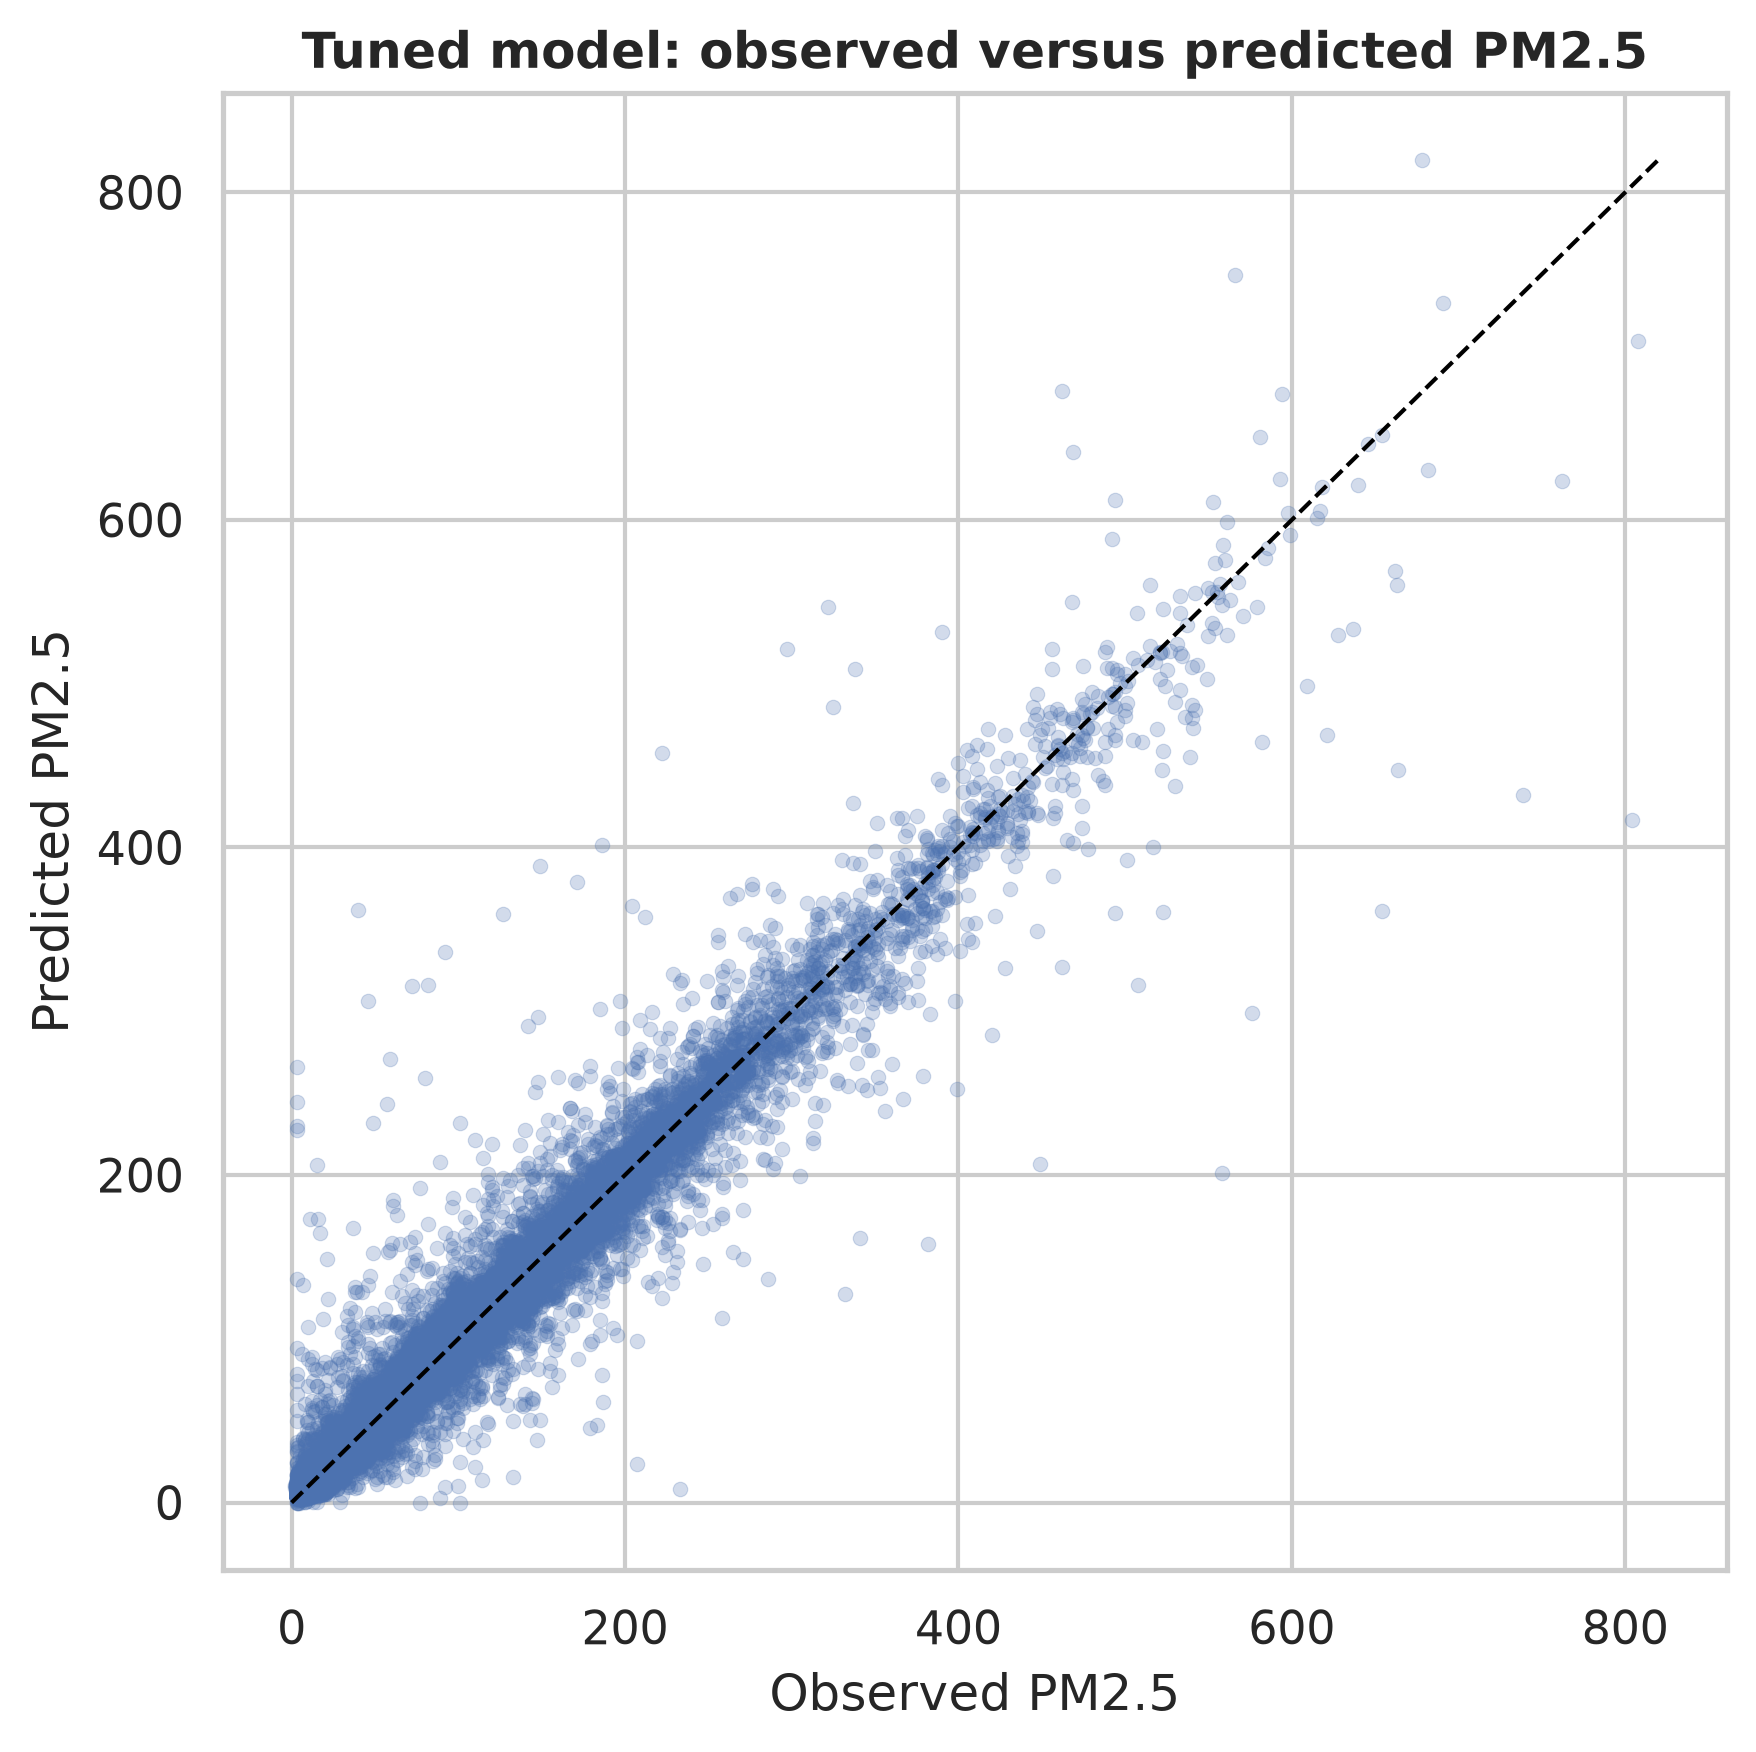

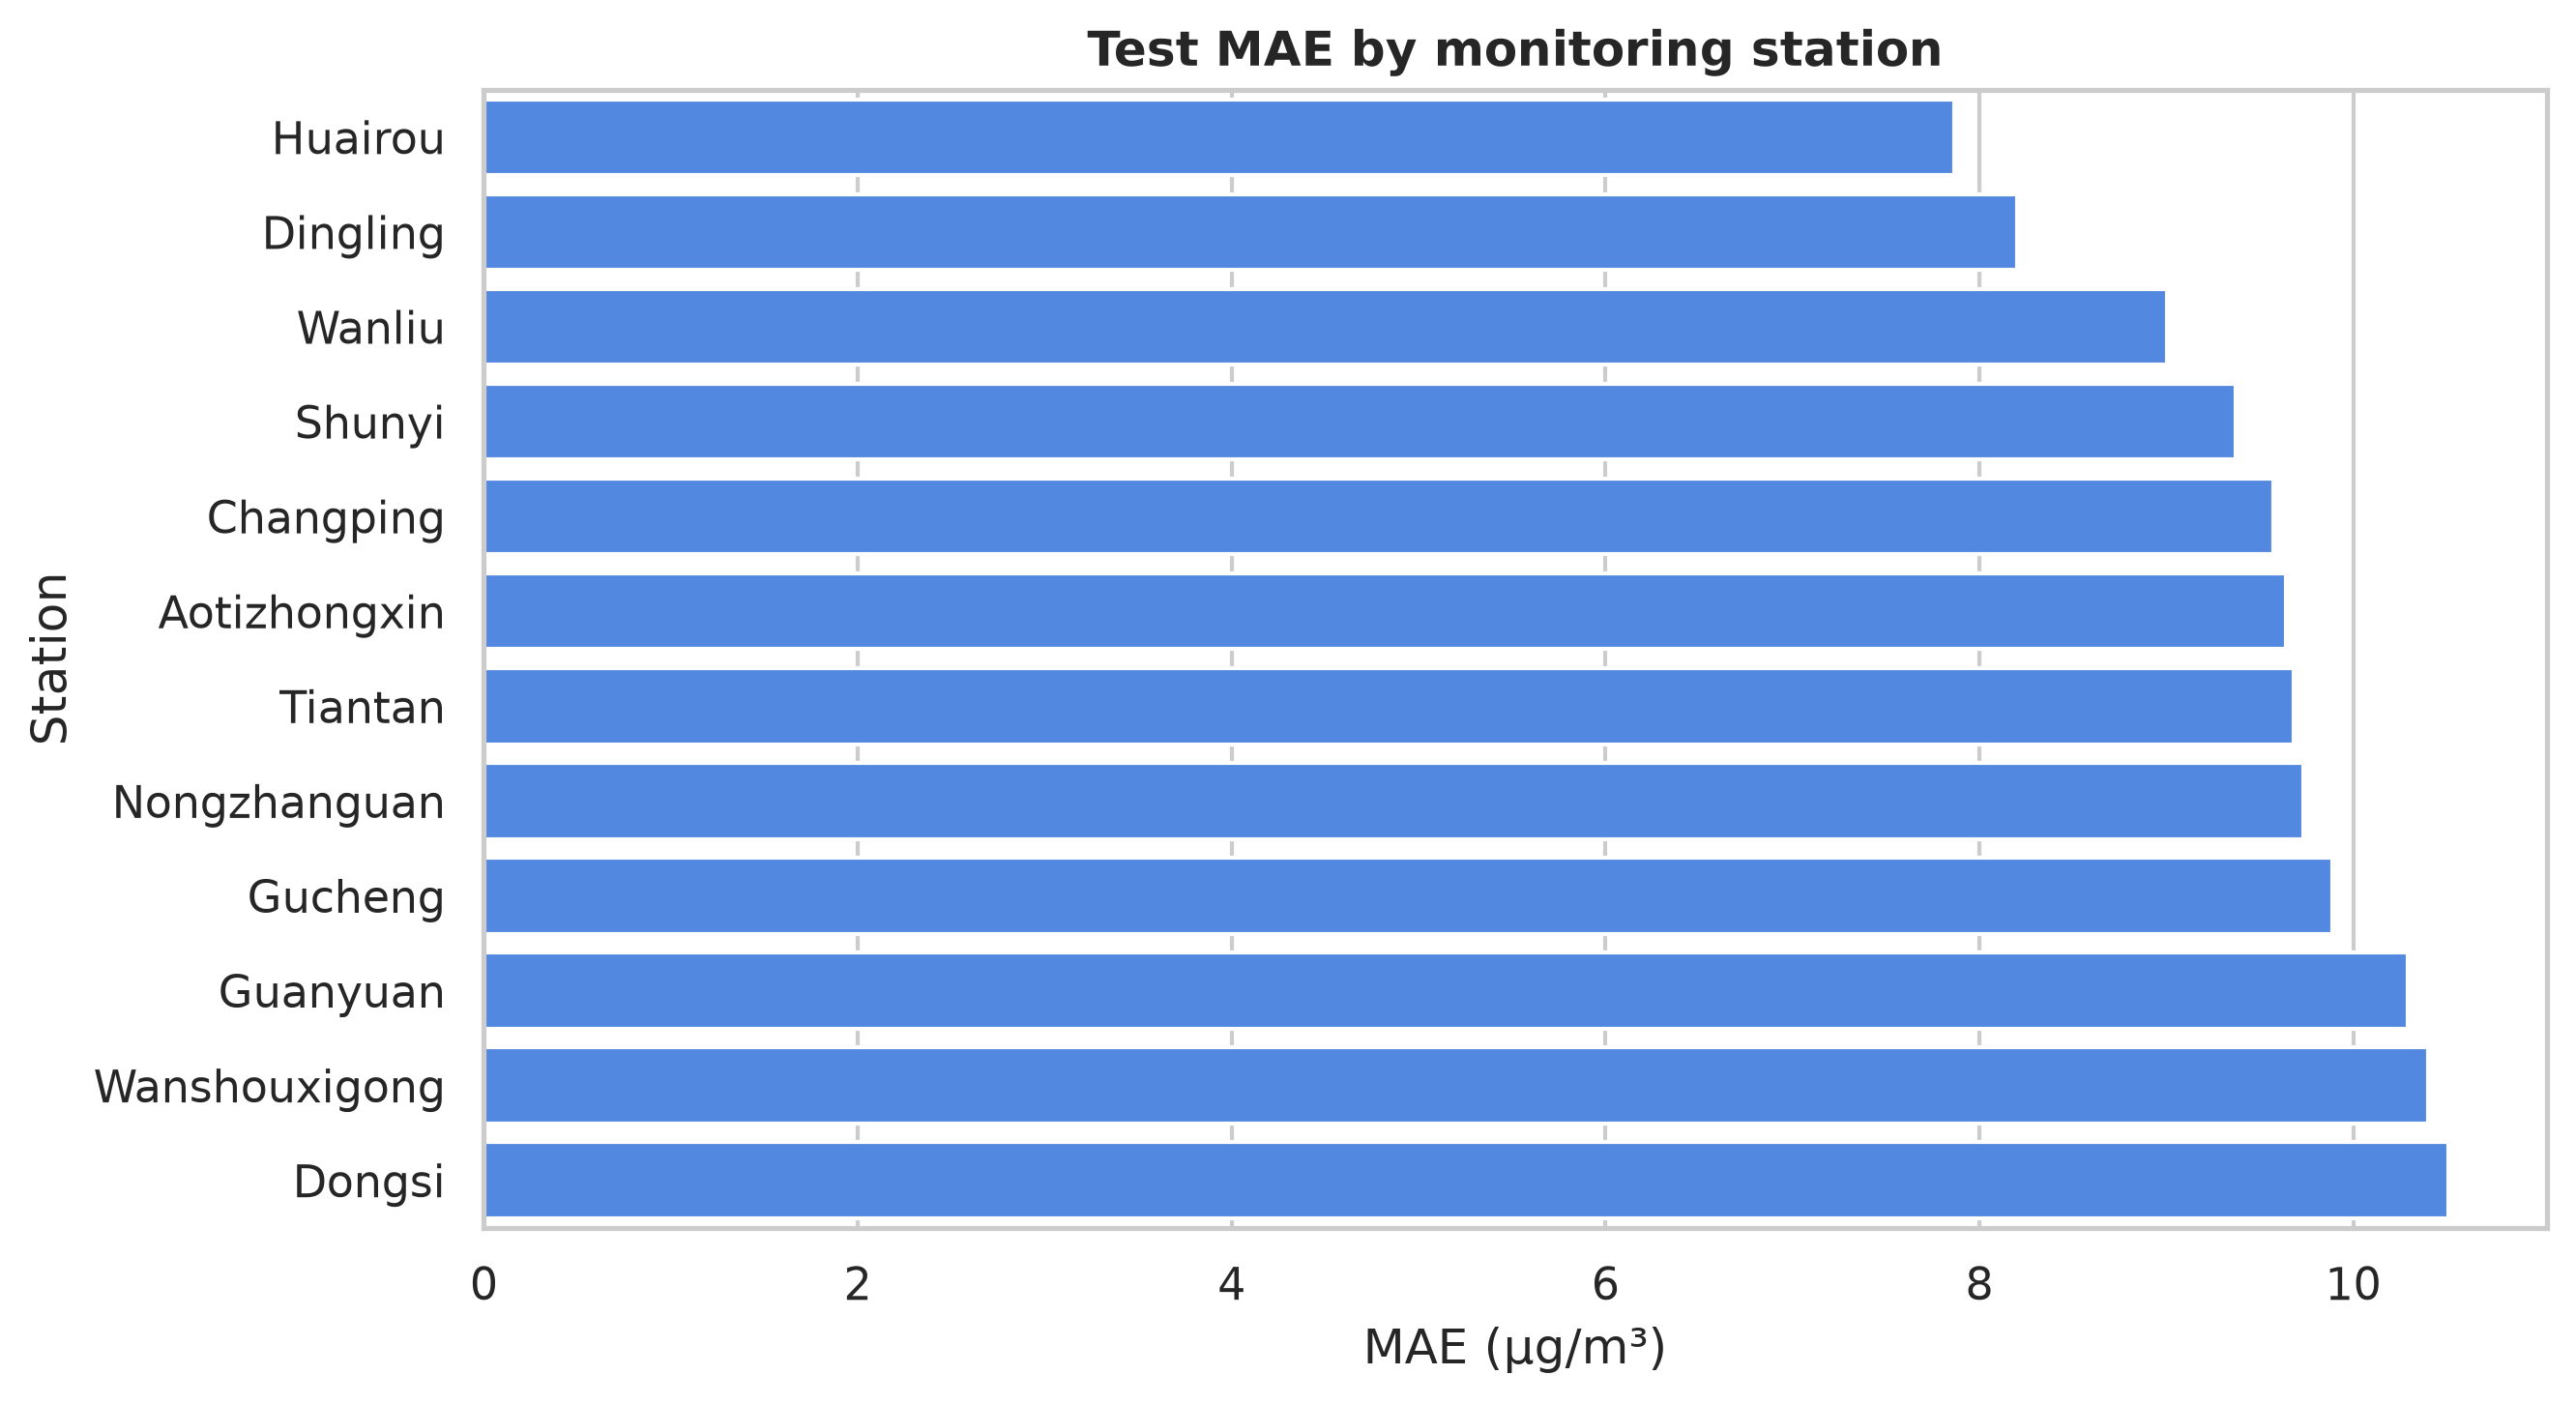

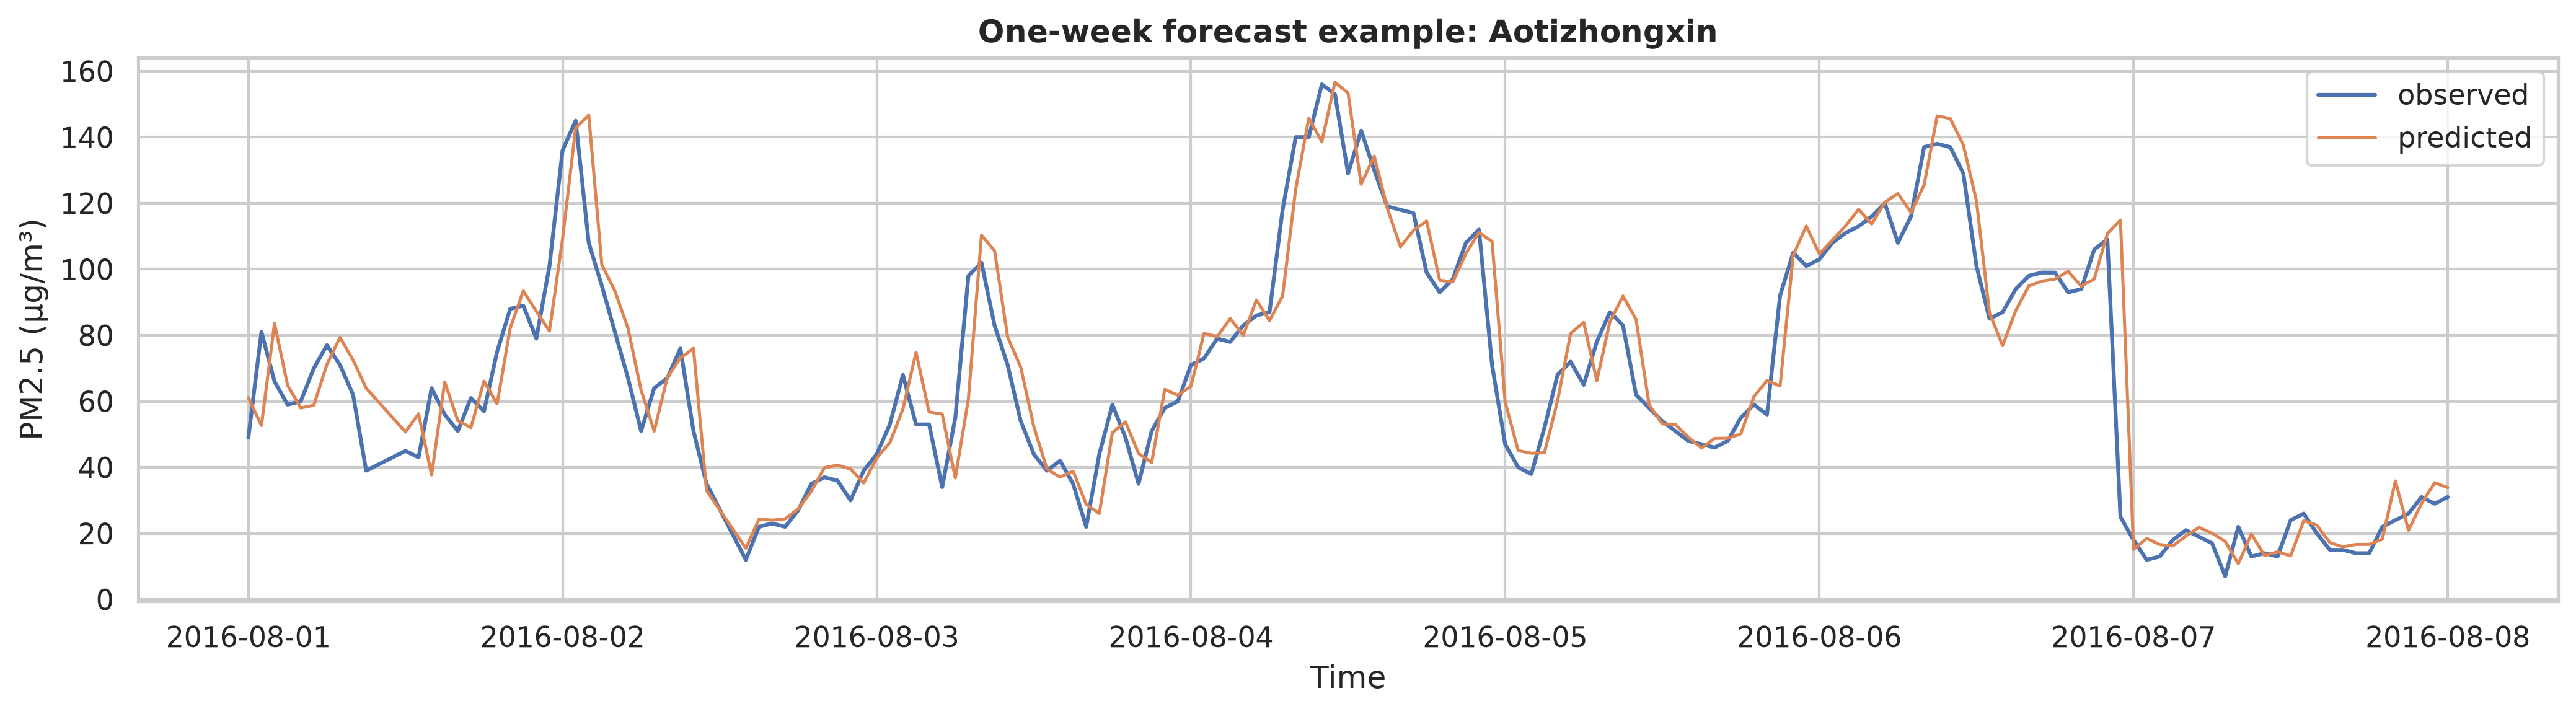

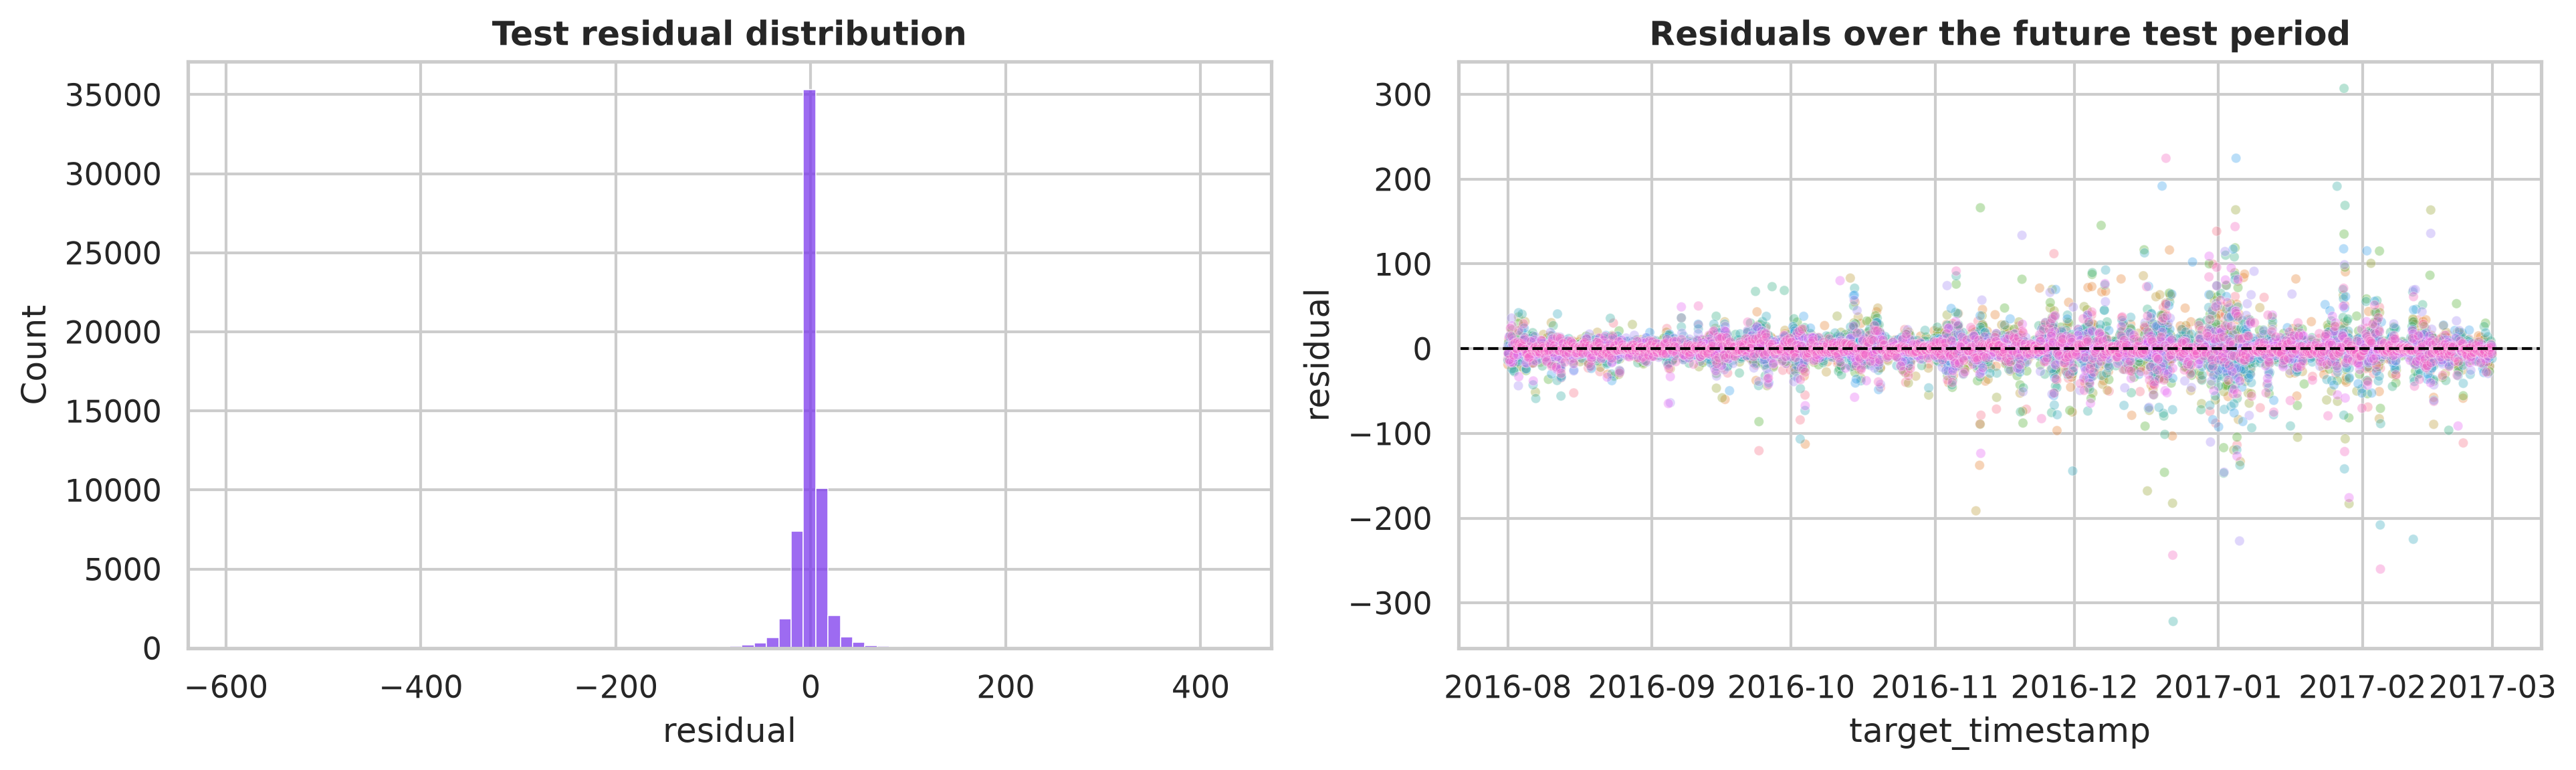

Published metrics are not directly comparable when datasets, horizons, splits, or preprocessing differ. Final benchmark evaluation complete.


In [6]:
bootstrap = pd.read_csv(
    PATHS.assignment2_tables / f"paired_moving_block_bootstrap{suffix}.csv"
)
display(bootstrap)
optimization_claim = json.loads(
    (PATHS.assignment2_tables / f"optimization_claim{suffix}.json").read_text(
        encoding="utf-8"
    )
)
display(optimization_claim)
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_actual_vs_predicted{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_station_mae{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_example_week{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_residual_analysis{suffix}.png"
)))
print(
    "Published metrics are not directly comparable when datasets, horizons, splits, "
    "or preprocessing differ. Final benchmark evaluation complete."
)
